# 군집화와 차원축소

In [ ]:
# 1단계. 같은 데이터, 정답만 빼기
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = data.data
y = data.target

print("데이터 모양:", X.shape)
print("특성 개수:", len(data.feature_names))
print("클래스 이름:", data.target_names)
print("정답 분포:", np.bincount(y), "(0=악성, 1=정상)")

데이터 모양: (569, 30)
특성 개수: 30
클래스 이름: ['malignant' 'benign']
정답 분포: [212 357] (0=악성, 1=정상)


In [ ]:
#2단계. 표준화가 왜 또 나오는가
print("가장 큰 분산:", round(X.var(axis=0).max(), 1),
      "| 가장 작은 분산:", round(X.var(axis=0).min(), 6))
print("비율:", round(X.var(axis=0).max() / X.var(axis=0).min(), 1), "배")

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("표준화 뒤 평균:", round(X_scaled.mean(),10),
      "| 표준편차:", round(X_scaled.std(), 6))


가장 큰 분산: 323597.7 | 가장 작은 분산: 7e-06
비율: 46298438340.4 배
표준화 뒤 평균: -0.0 | 표준편차: 1.0


In [ ]:
#3단계. K-평균 돌리기
from sklearn.cluster import KMeans

km = KMeans(n_clusters=2, n_init=10, random_state=42)
labels = km.fit_predict(X_scaled)

print("군집 크기:", np.bincount(labels))
print("중심 모양:", km.cluster_centers_.shape)
print("관성(inertis):", round(km.inertia_, 2))
print("반복 횟수:", km.n_iter_)

군집 크기: [375 194]
중심 모양: (2, 30)
관성(inertis): 11595.53
반복 횟수: 7


In [ ]:
#4단계. 맞았는지 어떻게 아는가
print(pd.crosstab(pd.Series(labels, name="군집"),
                            pd.Series(y, name="실제")))
acc_naive = (labels == y).mean()
acc_flip = (1 - labels == y).mean()
print("그대로 세면:", round(acc_naive, 4))
print("번호를 뒤집어 세면:", round(acc_flip, 4))

실제    0    1
군집          
0    36  339
1   176   18
그대로 세면: 0.0949
번호를 뒤집어 세면: 0.9051


In [ ]:
#5단계. 표준화를 안 하면
km_raw = KMeans(n_clusters=2, n_init=10, random_state=42)
labels_raw = km_raw.fit_predict(X)

print(pd.crosstab(pd.Series(labels_raw, name="군집"),
                  pd.Series(y, name="실제")))
gap = np.abs(km_raw.cluster_centers_[0] - km_raw.cluster_centers_[1])
order = np.argsort(gap)[::-1]
for i in order[:3]:
  print(" ", data.feature_names[i].ljust(24), round(gap[i], 3))

실제    0    1
군집          
0   130    1
1    82  356
  worst area               1133.375
  mean area                689.868
  area error               71.893


## 군집 수 선택

In [ ]:
#7단계. 엘보 방법
ks = range(2, 11)
inertias = []
for k in ks:
  m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
  inertias.append(m.inertia_)
  print("k =", k, "| 관성", round(m.inertia_, 1))
for i in range(1, len(inertias)):
  print(" ", list(ks)[i - 1], "→", list(ks)[i],
        ":", round(inertias[i - 1] - inertias[i], 1))

k = 2 | 관성 11595.5
k = 3 | 관성 10061.8
k = 4 | 관성 9259.0
k = 5 | 관성 8558.7
k = 6 | 관성 7970.3
k = 7 | 관성 7540.3
k = 8 | 관성 7254.3
k = 9 | 관성 6837.6
k = 10 | 관성 6603.4
  2 → 3 : 1533.7
  3 → 4 : 802.8
  4 → 5 : 700.3
  5 → 6 : 588.4
  6 → 7 : 429.9
  7 → 8 : 286.0
  8 → 9 : 416.7
  9 → 10 : 234.2


In [ ]:
#8단계. 실루엣 계산
from sklearn.metrics import silhouette_score, silhouette_samples

for k in ks:
  m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
  s = silhouette_score(X_scaled, m.labels_)
  print("k =", k, "| 실루엣", round(s, 4))

sv = silhouette_samples(X_scaled, labels)
print("점별 실루엣 최소", round(sv.min(), 4), "| 최대:", round(sv.max(), 4))
print("음수인 점:", int((sv < 0 ).sum()), "개 /", len(sv), "개")

k = 2 | 실루엣 0.3434
k = 3 | 실루엣 0.3144
k = 4 | 실루엣 0.2833
k = 5 | 실루엣 0.1582
k = 6 | 실루엣 0.1604
k = 7 | 실루엣 0.1532
k = 8 | 실루엣 0.1472
k = 9 | 실루엣 0.147
k = 10 | 실루엣 0.1367
점별 실루엣 최소 -0.1704 | 최대: 0.5869
음수인 점: 41 개 / 569 개


## K-평균이 못 하는 것

In [ ]:
#9단계. 시작 위치를 바꿔 보기
for n in [1, 2, 5, 10]:
  vals = []
  for seed in range(20):
    m = KMeans(n_clusters=5, n_init=n, random_state=seed).fit(X_scaled)
    vals.append(m.inertia_)
  vals = np.array(vals)
  print(str(n).rjust(6), "| 평균", round(vals.mean(), 2),
        "| 최저", round(vals.min(), 2),
        "| 최고", round(vals.max(), 2))

     1 | 평균 8667.69 | 최저 8553.48 | 최고 8936.13
     2 | 평균 8637.43 | 최저 8553.48 | 최고 8778.23
     5 | 평균 8581.83 | 최저 8553.48 | 최고 8700.5
    10 | 평균 8558.62 | 최저 8553.48 | 최고 8564.28


실제    0    1
군집          
0   113   38
1    37  112


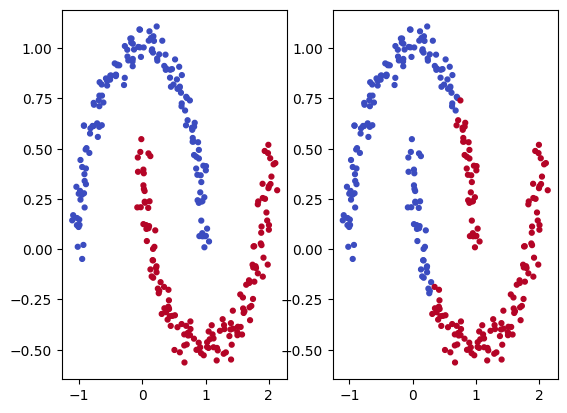

In [ ]:
#10단계. 원형이 아니면
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
Xm, ym = make_moons(n_samples=300, noise=0.05, random_state=42)
lm = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(Xm)
print(pd.crosstab(pd.Series(lm, name="군집"), pd.Series(ym, name="실제")))

plt.subplot(1, 2, 1)
plt.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=12)
plt.subplot(1, 2, 2)
plt.scatter(Xm[:, 0], Xm[:, 1], c=lm, cmap="coolwarm", s=12)
plt.show()

## 주성분분석

In [ ]:
#11단계. 30차원을 2차원으로
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("줄이기 전:", X_scaled.shape, "→ 줄인 뒤:", X_pca.shape)
print("설명된 분산 비율:", np.round(pca.explained_variance_ratio_, 4))
print("두 개로 설명하는 비율:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "퍼센트")

줄이기 전: (569, 30) → 줄인 뒤: (569, 2)
설명된 분산 비율: [0.4427 0.1897]
두 개로 설명하는 비율: 63.24 퍼센트


In [ ]:
#12단계. 몇 개까지 남길 것인가
full = PCA().fit(X_scaled)
cum = np.cumsum(full.explained_variance_ratio_)
for n in [1, 2, 3, 5, 7, 10, 17, 30]:
  print("주성분", str(n).rjust(2), "개 ->",
    str(round(cum[n - 1] * 100, 2)).rjust(6), "퍼센트")
for target in [0.8, 0.9, 0.95, 0.99]:
  need = int(np.argmax(cum >= target)) + 1
  print(int(target * 100), "퍼센트를 넘기려면 주성분", need, "개")

주성분  1 개 ->  44.27 퍼센트
주성분  2 개 ->  63.24 퍼센트
주성분  3 개 ->  72.64 퍼센트
주성분  5 개 ->  84.73 퍼센트
주성분  7 개 ->  91.01 퍼센트
주성분 10 개 ->  95.16 퍼센트
주성분 17 개 ->  99.11 퍼센트
주성분 30 개 ->  100.0 퍼센트
80 퍼센트를 넘기려면 주성분 5 개
90 퍼센트를 넘기려면 주성분 7 개
95 퍼센트를 넘기려면 주성분 10 개
99 퍼센트를 넘기려면 주성분 17 개


In [ ]:
#13단계. 새축은 무엇으로 만들어졌는가
w = pca.components_[0]
for i in np.argsort(np.abs(w))[::-1][:5]:
  print(" ", data.feature_names[i].ljust(24), round(w[i], 4))

print("1번 주성분 계수의 최소 절댓값:", round(np.abs(w).min(), 4))
print("계수가 0인 특성 개수:", int((np.abs(w) < 1e-12).sum()))

  mean concave points      0.2609
  mean concavity           0.2584
  worst concave points     0.2509
  mean compactness         0.2393
  worst perimeter          0.2366
1번 주성분 계수의 최소 절댓값: 0.0145
계수가 0인 특성 개수: 0
